# Employee attrition

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as srn

In [3]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
pd.set_option("display.max_columns",None)
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


### EDA

In [4]:
df.shape

(1470, 35)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [6]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [7]:
df.drop_duplicates(inplace=True)
df.shape

(1470, 35)

In [8]:
df.isnull().sum()
df.isnull().sum().sum()

np.int64(0)

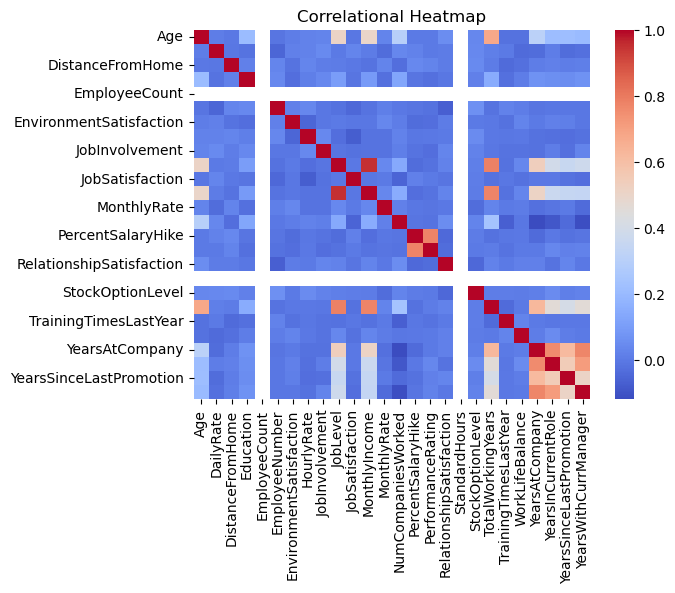

In [9]:
corr = data.corr(numeric_only=True)

srn.heatmap(corr,cmap='coolwarm')
plt.title('Correlational Heatmap')
plt.show()

In [10]:
df['EmployeeCount'].unique()

array([1])

In [11]:
df['StandardHours'].unique()

array([80])

In [12]:
df['Over18'].unique()

array(['Y'], dtype=object)

In [13]:
d1 = df.drop(columns=['Over18','StandardHours','EmployeeCount','EmployeeNumber'])
d1.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


### Visualization

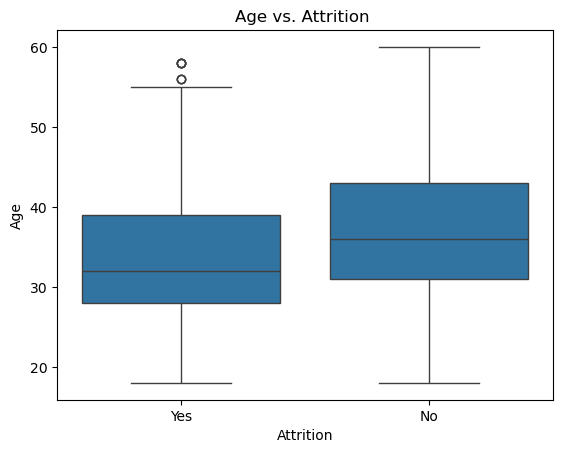

In [14]:
# age vs attrition

srn.boxplot(data=d1, x='Attrition', y='Age')
plt.title('Age vs. Attrition ')
plt.show()

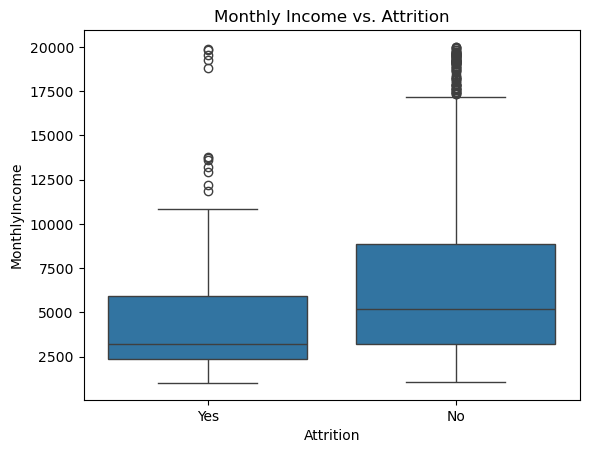

In [15]:
# MonthlyIncome vs. Attrition

srn.boxplot(data = d1, x = 'Attrition', y = 'MonthlyIncome')
plt.title('Monthly Income vs. Attrition')
plt.show()

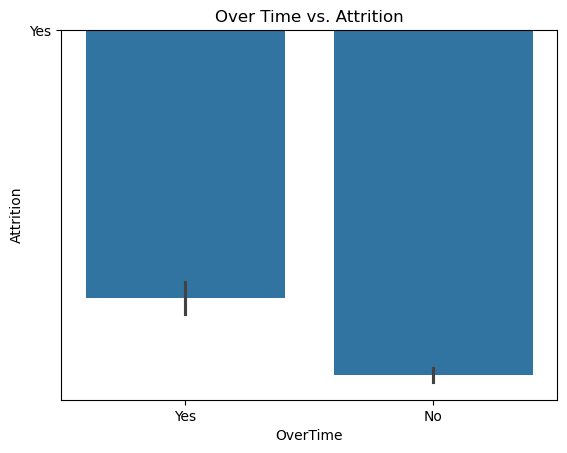

In [16]:
# Over Time vs. Attrition

srn.barplot(data = d1, x ='OverTime', y='Attrition')
plt.title('Over Time vs. Attrition')
plt.show()

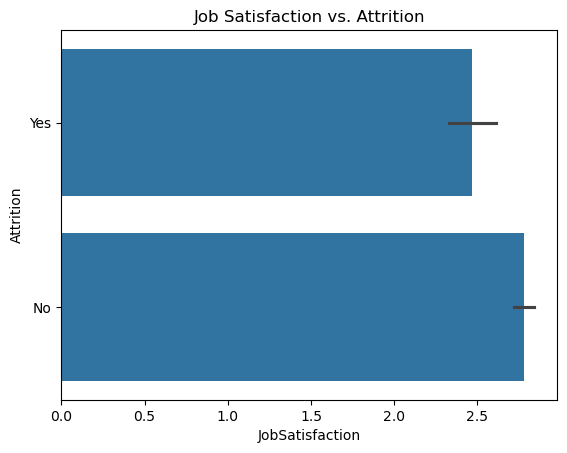

In [17]:
# Job Satisfaction vs. Attrition

srn.barplot(data=d1, x='JobSatisfaction',y='Attrition')
plt.title('Job Satisfaction vs. Attrition')
plt.show()

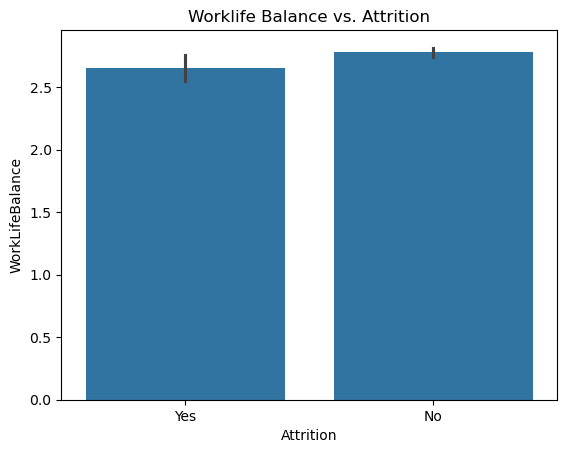

In [18]:
# worklife Balance vs. Attrition

srn.barplot(data=d1, x='Attrition', y='WorkLifeBalance')
plt.title('Worklife Balance vs. Attrition')
plt.show()

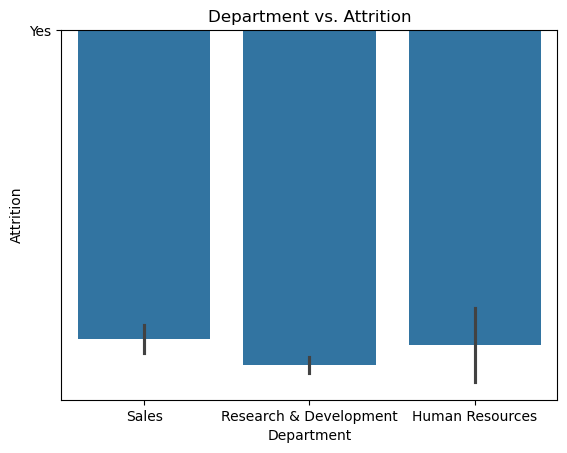

In [19]:
# Department vs. Attrition

srn.barplot(data=d1, x='Department', y='Attrition')
plt.title('Department vs. Attrition')
plt.show()

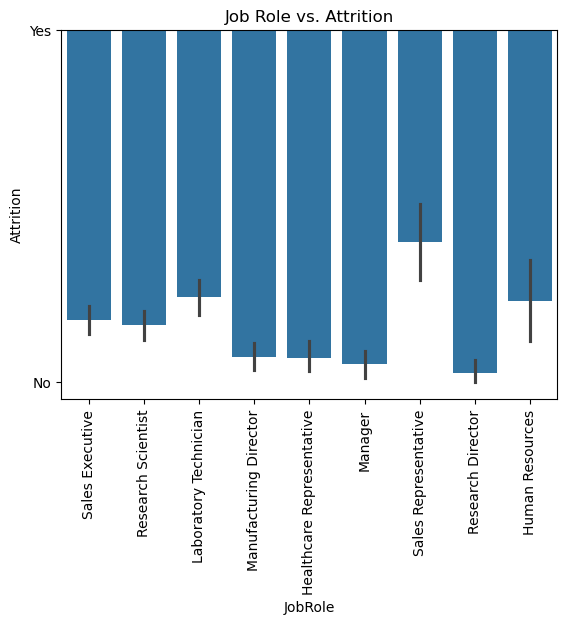

In [20]:
# Job Role vs. Attrition

srn.barplot(data=d1, x='JobRole', y='Attrition')
plt.xticks(rotation=90)
plt.title('Job Role vs. Attrition')
plt.show()

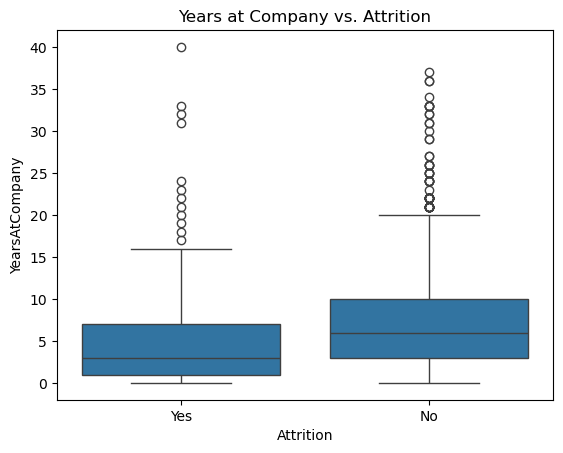

In [21]:
# Years at Company vs. Attrition

srn.boxplot(data=d1, x='Attrition', y='YearsAtCompany')
plt.title('Years at Company vs. Attrition')
plt.show()

In [22]:
d1['Attrition'] = d1['Attrition'].map({'Yes':1, 'No':0})
d1['Attrition'].unique()

array([1, 0])

### Splitting Dataset

In [23]:
x = d1.drop(columns=['Attrition'])
y = d1['Attrition']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=50)

x_train.shape, x_test.shape

((1176, 30), (294, 30))

### Encoding 

In [24]:
cat_col = x.select_dtypes(include=(object)).columns
num_col = x.select_dtypes(exclude=(object)).columns

In [25]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ('cat',OneHotEncoder(drop='first'),cat_col),
    ('num',StandardScaler(),num_col)
])

### LOGISTIC REGRESSION

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

lr_pipeline = Pipeline([
    ('processor',preprocessor),
    ('lr',LogisticRegression())
])

lr_pipeline.fit(x_train,y_train)

lr_ypre = lr_pipeline.predict(x_test)

lr_acc = accuracy_score(y_test,lr_ypre)
lr_precision = precision_score(y_test,lr_ypre)
lr_recall = recall_score(y_test,lr_ypre)
lr_f1 = f1_score(y_test,lr_ypre)

print("Accuracy Score :- ",lr_acc)
print('Precision Score :- ',lr_precision)
print("Recall Score :- ",lr_recall)
print("F1 Score :- ",lr_f1)

Accuracy Score :-  0.8707482993197279
Precision Score :-  0.7272727272727273
Recall Score :-  0.4528301886792453
F1 Score :-  0.5581395348837209


### KNN

In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ('processor',preprocessor),
    ('knn',KNeighborsClassifier(n_neighbors=2))
])

knn_pipeline.fit(x_train,y_train)

knn_ypre = knn_pipeline.predict(x_test)

k_acc = accuracy_score(y_test,knn_ypre)
k_precision = precision_score(y_test,knn_ypre)
k_recall = recall_score(y_test,knn_ypre)
k_f1 = f1_score(y_test,knn_ypre)

print("Accuracy Score :- ",k_acc)
print('Precision Score :- ',k_precision)
print("Recall Score :- ",k_recall)
print("F1 Score :- ",k_f1)

Accuracy Score :-  0.8197278911564626
Precision Score :-  0.5
Recall Score :-  0.018867924528301886
F1 Score :-  0.03636363636363636


### DECISION TREE

In [28]:
from sklearn.tree import DecisionTreeClassifier

dct_pipeline = Pipeline([
    ('processor',preprocessor),
    ('dct',DecisionTreeClassifier(random_state=42,max_depth=7,min_samples_split=100))
])

dct_pipeline.fit(x_train,y_train)

dct_ypre = dct_pipeline.predict(x_test)

dct_acc = accuracy_score(y_test,dct_ypre)
dct_precision = precision_score(y_test,dct_ypre)
dct_recall = recall_score(y_test,dct_ypre)
dct_f1 = f1_score(y_test,dct_ypre)

print("Accuracy Score :- ",dct_acc)
print('Precision Score :- ',dct_precision)
print("Recall Score :- ",dct_recall)
print("F1 Score :- ",dct_f1)

Accuracy Score :-  0.8163265306122449
Precision Score :-  0.0
Recall Score :-  0.0
F1 Score :-  0.0


### GRADIENT DECENT

In [29]:
from sklearn.ensemble import GradientBoostingClassifier

cls_pipeline = Pipeline([
    ('processor',preprocessor),
    ('cls',GradientBoostingClassifier(n_estimators=200,learning_rate=0.1))
])

cls_pipeline.fit(x_train,y_train)

cls_ypre = cls_pipeline.predict(x_test)

cls_acc = accuracy_score(y_test,cls_ypre)
cls_precision = precision_score(y_test,cls_ypre)
cls_recall = recall_score(y_test,cls_ypre)
cls_f1 = f1_score(y_test,cls_ypre)

print("Accuracy Score :- ",cls_acc)
print('Precision Score :- ',cls_precision)
print("Recall Score :- ",cls_recall)
print("F1 Score :- ",cls_f1)

Accuracy Score :-  0.8401360544217688
Precision Score :-  0.6153846153846154
Recall Score :-  0.3018867924528302
F1 Score :-  0.4050632911392405


### Comparing Models

In [30]:
results = pan.DataFrame({
    'Model':['Logistic Regression', 'KNN', 'Decision Tree', 'Gradient Boosting'],
    'Accuracy': [lr_acc, k_acc, dct_acc, cls_acc],
    'Precsion': [lr_precision, k_precision, dct_precision, cls_precision],
    'Recall' : [lr_recall, k_recall, dct_recall, cls_recall],
    'F1 Score' : [lr_f1, k_f1, dct_f1, cls_f1]
})

results

,Model,Accuracy,Precsion,Recall,F1 Score
0,Logistic Regression,0.870748,0.727273,0.452830,0.558140
1,KNN,0.819728,0.500000,0.018868,0.036364
2,Decision Tree,0.816327,0.000000,0.000000,0.000000
3,Gradient Boosting,0.840136,0.615385,0.301887,0.405063


In [31]:
best_model = 'Logistic Regression'
print("Selected best model :- ",best_model)

Selected best model :-  Logistic Regression


### Confusion Matrix

In [32]:
cm  = confusion_matrix(y_test,lr_ypre)
cm

array([[232,   9],
       [ 29,  24]])

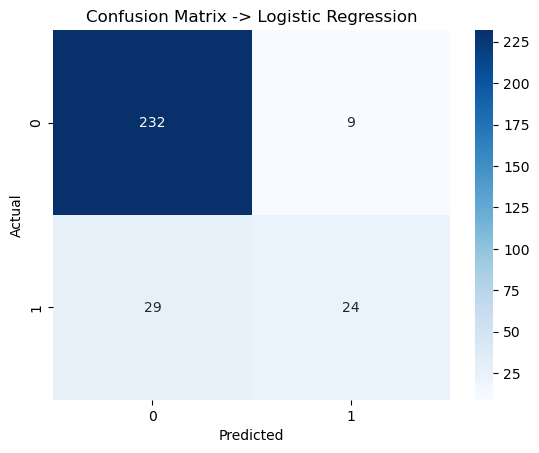

In [33]:
srn.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix -> Logistic Regression')
plt.show()

### Top 5 Features Affecting Attrition

In [34]:
# Feature importance using Decision Tree

importance = dct_pipeline['dct'].feature_importances_

fea_name = dct_pipeline['processor'].get_feature_names_out()

len(importance),len(fea_name)

feature_importance = pan.DataFrame({
    'Features' : fea_name,
    'Importance' : importance
})

feature_importance.head()

feature_importance = feature_importance.sort_values(by='Importance',ascending=False)
feature_importance.head()

top_5fea = feature_importance.head(5)
top_5fea

,Features,Importance
37,num__TotalWorkingYears,0.263576
30,num__MonthlyIncome,0.216082
20,cat__OverTime_Yes,0.178254
22,num__DailyRate,0.089741
16,cat__JobRole_Sales Executive,0.065462


In [35]:
# Feature Importance using Logistic Regression

feat_names = lr_pipeline['processor'].get_feature_names_out()

coeffs = lr_pipeline['lr'].coef_[0]

feat_importance = pan.DataFrame({
    'Feature': feat_names,
    'Coefficient': coeffs
})

feat_importance['Absolute_Coefficient'] = (
    feat_importance['Coefficient'].abs()
)

feat_importance = feat_importance.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

top_5 = feat_importance.head(5)

top_5

,Feature,Coefficient,Absolute_Coefficient
20,cat__OverTime_Yes,1.800570,1.800570
0,cat__BusinessTravel_Travel_Frequently,1.459306,1.459306
17,cat__JobRole_Sales Representative,1.161661,1.161661
11,cat__JobRole_Laboratory Technician,1.143349,1.143349
19,cat__MaritalStatus_Single,1.086226,1.086226


### Prediction for New Employee

In [36]:

new_employee = {
    'Age': 28,
    'BusinessTravel': 'Travel_Frequently',
    'DailyRate': 800,
    'Department': 'Research & Development',
    'DistanceFromHome': 10,
    'Education': 3,
    'EducationField': 'Life Sciences',
    'EnvironmentSatisfaction': 2,
    'Gender': 'Male',
    'HourlyRate': 70,
    'JobInvolvement': 3,
    'JobLevel': 1,
    'JobRole': 'Laboratory Technician',
    'JobSatisfaction': 2,
    'MaritalStatus': 'Single',
    'MonthlyIncome': 3500,
    'MonthlyRate': 15000,
    'NumCompaniesWorked': 2,
    'OverTime': 'Yes',
    'PercentSalaryHike': 12,
    'PerformanceRating': 3,
    'RelationshipSatisfaction': 2,
    'StockOptionLevel': 0,
    'TotalWorkingYears': 5,
    'TrainingTimesLastYear': 2,
    'WorkLifeBalance': 2,
    'YearsAtCompany': 2,
    'YearsInCurrentRole': 1,
    'YearsSinceLastPromotion': 0,
    'YearsWithCurrManager': 1
}

new_emp = pan.DataFrame([new_employee])

prediction = lr_pipeline.predict(new_emp)[0]
probability = lr_pipeline.predict_proba(new_emp)

prediction, probability

(np.int64(1), array([[0.07534909, 0.92465091]]))

In [37]:
if prediction == 1:
    result = 'Leave'
else:
    result = 'Stay'

probability_per = probability[0][1] * 100
probability

if probability_per < 30:
    risk = 'Low'
elif probability_per <= 60:
    risk = 'Medium'
else:
    risk = 'High'

In [38]:
print("Prediction :- ",result)
print("Attrition Probability :- ",round(probability_per, 2), "%")
print("Risk Level :- ",risk)

Prediction :-  Leave
Attrition Probability :-  92.47 %
Risk Level :-  High


# Give 5 HR Recommendations Based on the Analysis


Based on the employee attrition analysis, the following recommendations are suggested for the HR department:

1.Improve Salary and Benefits: Provide fair salaries, bonuses, and benefits to keep employees satisfied.
2.Provide Career Growth: Offer promotions, training, and learning opportunities to employees.
3.Maintain Work-Life Balance: Reduce workload and provide flexible working hours wherever possible.
4.Improve Employee Engagement: Conduct regular meetings, feedback sessions, and employee satisfaction surveys.
5.Identify High-Risk Employees: Use the attrition prediction model to identify employees who may leave and take preventive action.

# Conclusion

The Employee Attrition Prediction project helps organizations predict whether an employee is likely to leave or stay. The machine learning model analyzes employee details and provides an attrition prediction, probability, and risk level. This helps the HR department identify employees at risk and take timely action to improve employee satisfaction and retention.